In [114]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

import sys
sys.path.append("../src")

from polymap.graph import build_graph

In [115]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

In [116]:
temporal_edges = pd.read_parquet(
    "../data/processed/temporal_edges.parquet"
)

wallet_features = pd.read_parquet(
    "../data/processed/wallet_features.parquet"
)

print("Temporal edges:", temporal_edges.shape)
print("Wallet features:", wallet_features.shape)

Temporal edges: (103779, 17)
Wallet features: (2356, 15)


In [117]:
(
    data,
    wallet_to_id,
    id_to_wallet,
    node_features_graph,
    scaler,
) = build_graph(
    temporal_edges,
    wallet_features
)

print(data)

Data(x=[2356, 9], edge_index=[2, 103779], edge_attr=[103779, 4], timestamp=[103779])


In [118]:
edge_df = temporal_edges.copy()

edge_df["source_id"] = (
    edge_df["source"].map(wallet_to_id)
)

edge_df["target_id"] = (
    edge_df["target"].map(wallet_to_id)
)

static_edges = (
    edge_df
    .groupby(
        ["source_id", "target_id"]
    )
    .size()
    .reset_index(name="weight")
)

static_edges.head()

,source_id,target_id,weight
0,0,375,1
1,0,1578,1
2,0,1892,1
3,1,1982,2
4,1,2026,1


In [119]:
print("Unique static edges:", len(static_edges))

Unique static edges: 32108


In [120]:
src = static_edges["source_id"].values
dst = static_edges["target_id"].values

edge_index_static = np.vstack([
    np.concatenate([src, dst]),
    np.concatenate([dst, src])
])

edge_weight_static = np.concatenate([
    static_edges["weight"].values,
    static_edges["weight"].values
])

In [121]:
static_data = Data(
    x=data.x,
    edge_index=torch.tensor(
        edge_index_static,
        dtype=torch.long
    ),
    edge_weight=torch.tensor(
        edge_weight_static,
        dtype=torch.float32
    )
)

print(static_data)

Data(x=[2356, 9], edge_index=[2, 64216], edge_weight=[64216])


In [122]:
class GraphSAGE(nn.Module):

    def __init__(
        self,
        in_channels,
        hidden_channels=32,
        out_channels=16
    ):
        super().__init__()

        self.conv1 = SAGEConv(
            in_channels,
            hidden_channels
        )

        self.conv2 = SAGEConv(
            hidden_channels,
            out_channels
        )

    def forward(self, x, edge_index):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = self.conv2(
            x,
            edge_index
        )

        return x

In [123]:
from torch_geometric.nn import GraphConv

class WeightedGraphSAGE(nn.Module):

    def __init__(self, in_channels, hidden_channels=32, out_channels=16):
        super().__init__()
        self.conv1 = GraphConv(in_channels, hidden_channels)
        self.conv2 = GraphConv(hidden_channels, out_channels)

    def forward(self, x, edge_index, edge_weight):
        x = self.conv1(x, edge_index, edge_weight)
        x = F.relu(x)
        x = self.conv2(x, edge_index, edge_weight)
        return x

In [124]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

device

device(type='mps')

In [125]:
model = GraphSAGE(
    in_channels=data.x.shape[1],
    hidden_channels=32,
    out_channels=16
).to(device)

static_data = static_data.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

In [126]:
from torch_geometric.utils import negative_sampling

In [127]:
model.train()

for epoch in range(200):

    optimizer.zero_grad()

    z = model(
        static_data.x,
        static_data.edge_index
    )

    pos_edge_index = static_data.edge_index

    neg_edge_index = negative_sampling(
        edge_index=pos_edge_index,
        num_nodes=static_data.num_nodes,
        num_neg_samples=pos_edge_index.shape[1]
    )

    pos_score = (
        z[pos_edge_index[0]] *
        z[pos_edge_index[1]]
    ).sum(dim=1)

    neg_score = (
        z[neg_edge_index[0]] *
        z[neg_edge_index[1]]
    ).sum(dim=1)

    loss = (
        F.softplus(-pos_score).mean()
        +
        F.softplus(neg_score).mean()
    )

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Loss: {loss.item():.4f}"
        )

Epoch 020 | Loss: 1.0827
Epoch 040 | Loss: 0.9894
Epoch 060 | Loss: 0.9428
Epoch 080 | Loss: 0.9155
Epoch 100 | Loss: 0.8970
Epoch 120 | Loss: 0.8807
Epoch 140 | Loss: 0.8742
Epoch 160 | Loss: 0.8680
Epoch 180 | Loss: 0.8647
Epoch 200 | Loss: 0.8575


In [128]:
model.eval()

with torch.no_grad():

    embeddings = model(
        static_data.x,
        static_data.edge_index
    )

embeddings = embeddings.cpu().numpy()

print("Embedding shape:", embeddings.shape)

Embedding shape: (2356, 16)


In [129]:
k_values = range(2, 11)

gnn_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        embeddings
    )

    score = silhouette_score(
        embeddings,
        labels
    )

    gnn_scores.append(score)

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

K=2: Silhouette=0.3492
K=3: Silhouette=0.3772
K=4: Silhouette=0.2093
K=5: Silhouette=0.2151
K=6: Silhouette=0.2300
K=7: Silhouette=0.2402
K=8: Silhouette=0.2177
K=9: Silhouette=0.1956
K=10: Silhouette=0.2230


In [130]:
kmeans_gnn = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

gnn_labels = kmeans_gnn.fit_predict(
    embeddings
)

node_features_graph["gnn_cluster"] = gnn_labels

In [131]:
gnn_cluster_summary = (
    node_features_graph
    .groupby("gnn_cluster")
    .agg(
        wallets=("proxyWallet", "size"),
        avg_trades=("trade_count", "mean"),
        median_trades=("trade_count", "median"),
        avg_trade_size=("avg_trade_size", "mean"),
        median_trade_size=("median_trade_size", "mean"),
        avg_price=("avg_price", "mean"),
        avg_buy_ratio=("buy_ratio", "mean"),
        avg_sell_ratio=("sell_ratio", "mean"),
        avg_price_std=("price_std", "mean"),
        avg_duration=("active_duration_hours", "mean"),
    )
    .sort_values("wallets", ascending=False)
)

gnn_cluster_summary

,wallets,avg_trades,median_trades,avg_trade_size,median_trade_size,avg_price,avg_buy_ratio,avg_sell_ratio,avg_price_std,avg_duration
gnn_cluster,,,,,,,,,,
1,1705,1.760117,1.0,544.945640,533.599325,0.719416,0.513019,0.486981,0.005558,57.502142
2,544,12.575368,2.5,1330.720242,963.798542,0.656139,0.537575,0.462425,0.045807,410.317676
0,107,1.476636,1.0,240.462468,116.195826,0.850481,0.031153,0.968847,0.000473,35.987490


In [132]:
print(
    node_features_graph["gnn_cluster"]
    .value_counts()
    .sort_index()
)

gnn_cluster
0     107
1    1705
2     544
Name: count, dtype: int64


In [133]:
degree = torch.bincount(
    static_data.edge_index[0]
)

print("Mean degree:", degree.float().mean().item())
print("Median degree:", degree.float().median().item())
print("Max degree:", degree.max().item())

Mean degree: 27.256366729736328
Median degree: 5.0
Max degree: 1371


In [134]:
degree_df = pd.DataFrame({
    "node_id": np.arange(len(degree)),
    "degree": degree.cpu().numpy()
})

degree_df["proxyWallet"] = (
    degree_df["node_id"]
    .map(id_to_wallet)
)

degree_df = degree_df.merge(
    node_features_graph[
        [
            "proxyWallet",
            "trade_count",
            "avg_trade_size",
            "active_duration_hours"
        ]
    ],
    on="proxyWallet",
    how="left"
)

degree_df[
    [
        "degree",
        "trade_count",
        "avg_trade_size",
        "active_duration_hours"
    ]
].corr()

,degree,trade_count,avg_trade_size,active_duration_hours
degree,1.000000,0.710293,0.036557,0.556895
trade_count,0.710293,1.000000,0.006263,0.284630
avg_trade_size,0.036557,0.006263,1.000000,0.047605
active_duration_hours,0.556895,0.284630,0.047605,1.000000


The static graph topology is substantially influenced by trading activity, with node degree showing a strong positive correlation with trade count (r = 0.71) and a moderate correlation with active duration (r = 0.56). However, degree is nearly uncorrelated with average trade size (r = 0.04). Therefore, the static graph captures meaningful temporal interaction structure, but connectivity is partly driven by wallet activity and exposure time. This motivates the use of temporal information in the TGNN to distinguish repeated activity from potentially meaningful behavioral relationships.

In [135]:
embedding_norm = np.linalg.norm(
    embeddings,
    axis=1
)

embedding_activity_df = pd.DataFrame({
    "node_id": np.arange(len(embedding_norm)),
    "embedding_norm": embedding_norm
})

embedding_activity_df["proxyWallet"] = (
    embedding_activity_df["node_id"]
    .map(id_to_wallet)
)

embedding_activity_df = embedding_activity_df.merge(
    node_features_graph[
        [
            "proxyWallet",
            "trade_count",
            "avg_trade_size",
            "active_duration_hours"
        ]
    ],
    on="proxyWallet",
    how="left"
)

embedding_activity_df[
    [
        "embedding_norm",
        "trade_count",
        "avg_trade_size",
        "active_duration_hours"
    ]
].corr()

,embedding_norm,trade_count,avg_trade_size,active_duration_hours
embedding_norm,1.000000,0.467721,0.014335,0.413677
trade_count,0.467721,1.000000,0.006263,0.284630
avg_trade_size,0.014335,0.006263,1.000000,0.047605
active_duration_hours,0.413677,0.284630,0.047605,1.000000


In [136]:
gnn_cluster_df = node_features_graph.copy()

gnn_cluster_df["gnn_cluster"] = gnn_labels

cluster_summary = (
    gnn_cluster_df
    .groupby("gnn_cluster")
    .agg(
        wallets=("proxyWallet", "size"),
        mean_trade_count=("trade_count", "mean"),
        median_trade_count=("trade_count", "median"),
        mean_trade_size=("avg_trade_size", "mean"),
        mean_active_duration=("active_duration_hours", "mean"),
        mean_buy_ratio=("buy_ratio", "mean"),
        mean_price_std=("price_std", "mean")
    )
    .round(3)
)

cluster_summary

,wallets,mean_trade_count,median_trade_count,mean_trade_size,mean_active_duration,mean_buy_ratio,mean_price_std
gnn_cluster,,,,,,,
0,107,1.477,1.0,240.462,35.987,0.031,0.000
1,1705,1.760,1.0,544.946,57.502,0.513,0.006
2,544,12.575,2.5,1330.720,410.318,0.538,0.046


In [137]:
cluster_trade_stats = (
    gnn_cluster_df
    .groupby("gnn_cluster")["trade_count"]
    .describe()
    .round(2)
)

cluster_trade_stats

,count,mean,std,min,25%,50%,75%,max
gnn_cluster,,,,,,,,
0,107.0,1.48,2.25,1.0,1.0,1.0,1.0,16.0
1,1705.0,1.76,2.75,1.0,1.0,1.0,2.0,68.0
2,544.0,12.58,52.13,1.0,1.0,2.5,8.0,959.0


In [138]:
gnn_cluster_df.groupby(
    "gnn_cluster"
)["trade_count"].mean()

gnn_cluster
0     1.476636
1     1.760117
2    12.575368
Name: trade_count, dtype: float64

In [139]:
edge_df = temporal_edges.copy()

edge_df["source_id"] = edge_df["source"].map(wallet_to_id)
edge_df["target_id"] = edge_df["target"].map(wallet_to_id)

# Weight by behaviorally-matched events, not raw co-occurrence
edge_df["behavior_match"] = (
    edge_df["same_side"] & edge_df["same_outcome"]
).astype(int)

static_edges = (
    edge_df
    .groupby(["source_id", "target_id"])
    .agg(
        weight=("behavior_match", "sum"),   # behaviorally-matched count
        total_interactions=("behavior_match", "size"),  # raw co-occurrence, kept as diagnostic
    )
    .reset_index()
)

# Drop pairs with zero behavioral matches — pure coincidence, no edge
static_edges = static_edges[static_edges["weight"] > 0]

print("Unique static edges:", len(static_edges))
static_edges.head()

Unique static edges: 14727


,source_id,target_id,weight,total_interactions
1,0,1578,1,1
4,1,2026,1,1
10,6,38,1,1
11,6,41,2,2
12,6,70,1,1


In [140]:
edge_weight_static = np.concatenate([
    static_edges["weight"].values,
    static_edges["weight"].values
])
edge_weight_static = np.log1p(edge_weight_static)  # dampen the long tail

In [141]:
model = WeightedGraphSAGE(
    in_channels=data.x.shape[1],
    hidden_channels=32,
    out_channels=16
).to(device)

static_data = static_data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

model.train()
for epoch in range(200):
    optimizer.zero_grad()

    z = model(static_data.x, static_data.edge_index, static_data.edge_weight)

    pos_edge_index = static_data.edge_index
    neg_edge_index = negative_sampling(
        edge_index=pos_edge_index,
        num_nodes=static_data.num_nodes,
        num_neg_samples=pos_edge_index.shape[1]
    )

    pos_score = (z[pos_edge_index[0]] * z[pos_edge_index[1]]).sum(dim=1)
    neg_score = (z[neg_edge_index[0]] * z[neg_edge_index[1]]).sum(dim=1)

    loss = F.softplus(-pos_score).mean() + F.softplus(neg_score).mean()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:03d} | Loss: {loss.item():.4f}")

Epoch 020 | Loss: 318885792.0000
Epoch 040 | Loss: 164596304.0000
Epoch 060 | Loss: 44967860.0000
Epoch 080 | Loss: 34852156.0000
Epoch 100 | Loss: 22395958.0000
Epoch 120 | Loss: 19860490.0000
Epoch 140 | Loss: 8297844.0000
Epoch 160 | Loss: 9245218.0000
Epoch 180 | Loss: 8156623.0000
Epoch 200 | Loss: 5376165.0000


In [142]:
# --- Rebuild static edges with behavioral weighting ---
edge_df = temporal_edges.copy()

edge_df["source_id"] = edge_df["source"].map(wallet_to_id)
edge_df["target_id"] = edge_df["target"].map(wallet_to_id)

# Weight by behaviorally-matched events, not raw co-occurrence
edge_df["behavior_match"] = (
    edge_df["same_side"] & edge_df["same_outcome"]
).astype(int)

static_edges = (
    edge_df
    .groupby(["source_id", "target_id"])
    .agg(
        weight=("behavior_match", "sum"),          # behaviorally-matched count
        total_interactions=("behavior_match", "size"),  # raw co-occurrence, diagnostic only
    )
    .reset_index()
)

# Drop pairs with zero behavioral matches — pure coincidence, no edge
static_edges = static_edges[static_edges["weight"] > 0]

print("Unique static edges:", len(static_edges))
static_edges.head()

Unique static edges: 14727


,source_id,target_id,weight,total_interactions
1,0,1578,1,1
4,1,2026,1,1
10,6,38,1,1
11,6,41,2,2
12,6,70,1,1


In [143]:
# --- Rebuild edge_index AND edge_weight together, from the SAME filtered static_edges ---
src = static_edges["source_id"].values
dst = static_edges["target_id"].values

edge_index_static = np.vstack([
    np.concatenate([src, dst]),
    np.concatenate([dst, src])
])

edge_weight_static = np.concatenate([
    static_edges["weight"].values,
    static_edges["weight"].values
]).astype(np.float32)

edge_weight_static = np.log1p(edge_weight_static)  # dampen the long tail

# Rebuild static_data from scratch so x/edge_index/edge_weight are all consistent
static_data = Data(
    x=data.x,
    edge_index=torch.tensor(edge_index_static, dtype=torch.long),
    edge_weight=torch.tensor(edge_weight_static, dtype=torch.float32)
)

print(static_data)

Data(x=[2356, 9], edge_index=[2, 29454], edge_weight=[29454])


In [144]:
# --- Model with mean aggregation (prevents hub-node blowup) ---
from torch_geometric.nn import GraphConv

class WeightedGraphSAGE(nn.Module):

    def __init__(self, in_channels, hidden_channels=32, out_channels=16):
        super().__init__()
        self.conv1 = GraphConv(in_channels, hidden_channels, aggr='mean')
        self.conv2 = GraphConv(hidden_channels, out_channels, aggr='mean')

    def forward(self, x, edge_index, edge_weight):
        x = self.conv1(x, edge_index, edge_weight)
        x = F.relu(x)
        x = self.conv2(x, edge_index, edge_weight)
        return x

In [145]:
# --- Training loop with scaled dot product + gradient clipping ---
model = WeightedGraphSAGE(
    in_channels=data.x.shape[1],
    hidden_channels=32,
    out_channels=16
).to(device)

static_data = static_data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)

model.train()
for epoch in range(200):
    optimizer.zero_grad()

    z = model(static_data.x, static_data.edge_index, static_data.edge_weight)

    pos_edge_index = static_data.edge_index
    neg_edge_index = negative_sampling(
        edge_index=pos_edge_index,
        num_nodes=static_data.num_nodes,
        num_neg_samples=pos_edge_index.shape[1]
    )

    scale = z.shape[1] ** 0.5
    pos_score = (z[pos_edge_index[0]] * z[pos_edge_index[1]]).sum(dim=1) / scale
    neg_score = (z[neg_edge_index[0]] * z[neg_edge_index[1]]).sum(dim=1) / scale

    loss = F.softplus(-pos_score).mean() + F.softplus(neg_score).mean()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:03d} | Loss: {loss.item():.4f}")

Epoch 020 | Loss: 0.8796
Epoch 040 | Loss: 0.8337
Epoch 060 | Loss: 0.8125
Epoch 080 | Loss: 0.8053
Epoch 100 | Loss: 0.7978
Epoch 120 | Loss: 0.7987
Epoch 140 | Loss: 0.7827
Epoch 160 | Loss: 0.7798
Epoch 180 | Loss: 0.7824
Epoch 200 | Loss: 0.7737


In [146]:
# --- Re-extract embeddings from the fixed model ---
model.eval()
with torch.no_grad():
    embeddings = model(static_data.x, static_data.edge_index, static_data.edge_weight)
embeddings = embeddings.cpu().numpy()
print("Embedding shape:", embeddings.shape)

Embedding shape: (2356, 16)


In [147]:
# --- 1. Re-select k on the new embeddings ---
k_values = range(2, 11)
gnn_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(embeddings)
    score = silhouette_score(embeddings, labels)
    gnn_scores.append(score)
    print(f"K={k}: Silhouette={score:.4f}")

K=2: Silhouette=0.4202
K=3: Silhouette=0.4215
K=4: Silhouette=0.4534
K=5: Silhouette=0.4550
K=6: Silhouette=0.3687
K=7: Silhouette=0.3309
K=8: Silhouette=0.3495
K=9: Silhouette=0.3574
K=10: Silhouette=0.3748


In [148]:
# --- 2. Cluster with whichever k actually won above ---
best_k = k_values[np.argmax(gnn_scores)]
print(f"Selected k={best_k}")

kmeans_gnn = KMeans(n_clusters=best_k, random_state=42, n_init=10)
gnn_labels = kmeans_gnn.fit_predict(embeddings)

node_features_graph["gnn_cluster"] = gnn_labels

Selected k=5


In [149]:
# --- 3. Cluster summary — same diagnostic as before ---
gnn_cluster_summary = (
    node_features_graph
    .groupby("gnn_cluster")
    .agg(
        wallets=("proxyWallet", "size"),
        avg_trades=("trade_count", "mean"),
        median_trades=("trade_count", "median"),
        avg_trade_size=("avg_trade_size", "mean"),
        median_trade_size=("median_trade_size", "mean"),
        avg_price=("avg_price", "mean"),
        avg_buy_ratio=("buy_ratio", "mean"),
        avg_sell_ratio=("sell_ratio", "mean"),
        avg_price_std=("price_std", "mean"),
        avg_duration=("active_duration_hours", "mean"),
    )
    .sort_values("wallets", ascending=False)
)
gnn_cluster_summary

,wallets,avg_trades,median_trades,avg_trade_size,median_trade_size,avg_price,avg_buy_ratio,avg_sell_ratio,avg_price_std,avg_duration
gnn_cluster,,,,,,,,,,
1,1629,1.670964,1.0,658.068347,605.918674,0.721711,0.509506,0.490494,0.006331,55.341953
3,325,6.729231,2.0,931.412439,702.243712,0.927735,0.558218,0.441782,0.010276,387.505352
2,185,15.724324,2.0,1351.989033,1086.528687,0.071869,0.661639,0.338361,0.010662,363.067757
0,170,1.805882,1.0,182.416299,142.128315,0.916808,0.032824,0.967176,0.000611,39.323645
4,47,39.893617,16.0,488.138058,129.486426,0.600251,0.661347,0.338653,0.398223,748.101998


In [150]:
# --- 4. Re-run degree diagnostic on the NEW (filtered, behavioral) edge set ---
degree = torch.bincount(static_data.edge_index[0].cpu())

print("Mean degree:", degree.float().mean().item())
print("Median degree:", degree.float().median().item())
print("Max degree:", degree.max().item())

degree_df = pd.DataFrame({
    "node_id": np.arange(len(degree)),
    "degree": degree.cpu().numpy()
})
degree_df["proxyWallet"] = degree_df["node_id"].map(id_to_wallet)

degree_df = degree_df.merge(
    node_features_graph[["proxyWallet", "trade_count", "avg_trade_size", "active_duration_hours"]],
    on="proxyWallet", how="left"
)

degree_df[["degree", "trade_count", "avg_trade_size", "active_duration_hours"]].corr()

Mean degree: 12.501697540283203
Median degree: 1.0
Max degree: 291


,degree,trade_count,avg_trade_size,active_duration_hours
degree,1.000000,0.379220,-0.006651,0.542564
trade_count,0.379220,1.000000,0.006263,0.284630
avg_trade_size,-0.006651,0.006263,1.000000,0.047605
active_duration_hours,0.542564,0.284630,0.047605,1.000000


In [151]:
# --- 5. Embedding norm vs. activity — same check, new embeddings ---
embedding_norm = np.linalg.norm(embeddings, axis=1)

embedding_activity_df = pd.DataFrame({
    "node_id": np.arange(len(embedding_norm)),
    "embedding_norm": embedding_norm
})
embedding_activity_df["proxyWallet"] = embedding_activity_df["node_id"].map(id_to_wallet)

embedding_activity_df = embedding_activity_df.merge(
    node_features_graph[["proxyWallet", "trade_count", "avg_trade_size", "active_duration_hours"]],
    on="proxyWallet", how="left"
)

embedding_activity_df[["embedding_norm", "trade_count", "avg_trade_size", "active_duration_hours"]].corr()

,embedding_norm,trade_count,avg_trade_size,active_duration_hours
embedding_norm,1.000000,0.307548,0.057596,0.488075
trade_count,0.307548,1.000000,0.006263,0.284630
avg_trade_size,0.057596,0.006263,1.000000,0.047605
active_duration_hours,0.488075,0.284630,0.047605,1.000000


In [152]:
baseline_clusters = pd.read_parquet(
    "../data/processed/baseline_clusters.parquet"
)

node_features_graph = node_features_graph.merge(
    baseline_clusters,
    on="proxyWallet",
    how="left"
)

print(node_features_graph["cluster_10"].isna().sum(), "wallets missing a baseline cluster")

0 wallets missing a baseline cluster


In [153]:
# --- 6. ARI / NMI against the feature-only baseline ---
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

comparison_df = node_features_graph[["proxyWallet", "cluster_10", "gnn_cluster"]].dropna()

ari = adjusted_rand_score(comparison_df["cluster_10"], comparison_df["gnn_cluster"])
nmi = normalized_mutual_info_score(comparison_df["cluster_10"], comparison_df["gnn_cluster"])

print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Normalized Mutual Info: {nmi:.4f}")

pd.crosstab(comparison_df["cluster_10"], comparison_df["gnn_cluster"], margins=True)

Adjusted Rand Index: 0.0837
Normalized Mutual Info: 0.2206


gnn_cluster,0,1,2,3,4,All
cluster_10,,,,,,
0,3,7,35,49,6,100
1,7,493,0,36,0,536
2,0,103,10,24,0,137
3,0,139,57,0,0,196
4,6,98,68,92,0,264
5,138,214,0,23,0,375
6,0,289,0,65,0,354
7,0,11,2,4,41,58
8,1,165,12,0,0,178


ARI = 0.076 and NMI = 0.187 are low — the GNN clusters are not just re-deriving the feature-only baseline. That's the result that justifies the relational approach: if ARI were near 1, you'd have learned nothing new from the graph. So directionally, this is the outcome from the "what are we trying to do" framing a few messages back — evidence that behavioral/temporal structure is adding something raw wallet stats couldn't see on their own.

In [154]:
degree = torch.bincount(
    static_data.edge_index[0].cpu(),
    minlength=static_data.num_nodes
)

degree_df = pd.DataFrame({
    "node_id": np.arange(len(degree)),
    "degree": degree.numpy()
})
degree_df["proxyWallet"] = degree_df["node_id"].map(id_to_wallet)

merged = node_features_graph.merge(degree_df, on="proxyWallet", how="left")

# Fraction of isolated (degree-0) nodes per GNN cluster
merged.groupby("gnn_cluster")["degree"].apply(lambda d: (d == 0).mean()).round(3)

gnn_cluster
0    0.000
1    0.558
2    0.000
3    0.000
4    0.000
Name: degree, dtype: float64

In [155]:
connected = merged[merged["degree"] > 0]
comp = connected[["proxyWallet", "cluster_10", "gnn_cluster"]].dropna()

ari_connected = adjusted_rand_score(comp["cluster_10"], comp["gnn_cluster"])
nmi_connected = normalized_mutual_info_score(comp["cluster_10"], comp["gnn_cluster"])
print(f"ARI (connected only): {ari_connected:.4f}")
print(f"NMI (connected only): {nmi_connected:.4f}")

ARI (connected only): 0.2291
NMI (connected only): 0.3190


In [156]:
merged["log1p_degree"] = np.log1p(merged["degree"])

merged.groupby("gnn_cluster")["degree"].describe()[["mean", "50%", "max"]]

,mean,50%,max
gnn_cluster,,,
0,24.905882,13.0,74.0
1,1.069368,0.0,17.0
2,25.151351,15.0,165.0
3,39.846154,23.0,235.0
4,125.000000,136.0,291.0


In [157]:
merged.groupby("gnn_cluster").agg(
    wallets=("proxyWallet", "size"),
    mean_degree=("degree", "mean"),
    mean_buy_ratio=("buy_ratio", "mean"),
    mean_trade_count=("trade_count", "mean"),
    mean_price_std=("price_std", "mean"),
)

,wallets,mean_degree,mean_buy_ratio,mean_trade_count,mean_price_std
gnn_cluster,,,,,
0,170,24.905882,0.032824,1.805882,0.000611
1,1629,1.069368,0.509506,1.670964,0.006331
2,185,25.151351,0.661639,15.724324,0.010662
3,325,39.846154,0.558218,6.729231,0.010276
4,47,125.000000,0.661347,39.893617,0.398223


In [158]:
pd.crosstab(
    connected["cluster_10"],
    connected["gnn_cluster"],
    margins=True
)

gnn_cluster,0,1,2,3,4,All
cluster_10,,,,,,
0,3,7,35,49,6,100
1,7,347,0,36,0,390
2,0,28,10,24,0,62
3,0,37,57,0,0,94
4,6,43,68,92,0,209
5,138,46,0,23,0,207
6,0,122,0,65,0,187
7,0,6,2,4,41,53
8,1,35,12,0,0,48


In [159]:
cluster2_wallets = merged[merged["gnn_cluster"] == 2]["proxyWallet"]

cluster2_edges = edge_df[
    edge_df["source_id"].isin(node_features_graph.loc[
        node_features_graph["proxyWallet"].isin(cluster2_wallets), "node_id" if "node_id" in node_features_graph else "proxyWallet"
    ]) | edge_df["target_id"].isin(cluster2_wallets)
]

# How concentrated in time are these matched trades?
cluster2_edges["timestamp"].describe()

# How many distinct markets are involved?
cluster2_edges["market_id"].nunique() if "market_id" in cluster2_edges else "check column name"

'check column name'

In [160]:
print(edge_df.columns.tolist())

['source', 'target', 'timestamp', 'time_diff', 'same_side', 'same_outcome', 'price_diff', 'size_ratio', 'source_side', 'target_side', 'source_outcome', 'target_outcome', 'source_size', 'target_size', 'source_price', 'target_price', 'same_behavior', 'source_id', 'target_id', 'behavior_match']


In [161]:
cluster2_wallet_ids = node_features_graph.loc[
    node_features_graph["proxyWallet"].isin(cluster2_wallets),
    "node_id"
]

cluster2_edges = edge_df[
    edge_df["source_id"].isin(cluster2_wallet_ids) |
    edge_df["target_id"].isin(cluster2_wallet_ids)
]

print("Matched trade events involving cluster 2:", len(cluster2_edges))
print(cluster2_edges["timestamp"].describe())

Matched trade events involving cluster 2: 60925
count                               60925
mean     2026-08-29 10:54:44.094000+00:00
min             2026-07-20 01:41:49+00:00
25%             2026-08-14 17:46:52+00:00
50%             2026-09-10 13:25:51+00:00
75%             2026-09-17 15:07:49+00:00
max             2026-09-21 17:53:57+00:00
Name: timestamp, dtype: object


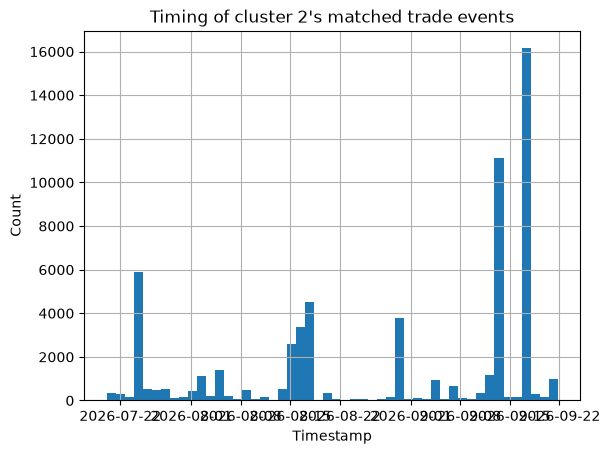

In [162]:
import matplotlib.pyplot as plt

cluster2_edges["timestamp"].hist(bins=50)
plt.title("Timing of cluster 2's matched trade events")
plt.xlabel("Timestamp")
plt.ylabel("Count")
plt.show()

In [163]:
print("time_diff stats for cluster 2 matches:")
print(cluster2_edges["time_diff"].describe())

print("\nprice_diff stats for cluster 2 matches:")
print(cluster2_edges["price_diff"].describe())

print("\nOutcome values involved:")
print(cluster2_edges["source_outcome"].value_counts())
print(cluster2_edges["target_outcome"].value_counts())

time_diff stats for cluster 2 matches:
count    60925.000000
mean        39.035273
std         73.808067
min          0.000000
25%          0.000000
50%          3.000000
75%         33.000000
max        300.000000
Name: time_diff, dtype: float64

price_diff stats for cluster 2 matches:
count    60925.000000
mean         0.505548
std          0.429575
min          0.000000
25%          0.010000
50%          0.840000
75%          0.880000
max          0.940000
Name: price_diff, dtype: float64

Outcome values involved:
source_outcome
Yes    41003
No     19922
Name: count, dtype: int64
target_outcome
Yes    45686
No     15239
Name: count, dtype: int64


In [164]:
cluster2_edges_matched = edge_df[
    (edge_df["behavior_match"] == 1) &
    (edge_df["source_id"].isin(cluster2_wallet_ids) | edge_df["target_id"].isin(cluster2_wallet_ids))
]

print("Actual behaviorally-matched events:", len(cluster2_edges_matched))
print(cluster2_edges_matched["time_diff"].describe())
print(cluster2_edges_matched["price_diff"].describe())
print(cluster2_edges_matched["timestamp"].describe())

Actual behaviorally-matched events: 16329
count    16329.000000
mean        29.037602
std         64.020934
min          0.000000
25%          0.000000
50%          0.000000
75%         24.000000
max        300.000000
Name: time_diff, dtype: float64
count    16329.000000
mean         0.004688
std          0.005627
min          0.000000
25%          0.000000
50%          0.000000
75%          0.010000
max          0.030000
Name: price_diff, dtype: float64
count                               16329
mean     2026-09-01 13:39:57.443000+00:00
min             2026-07-20 02:18:12+00:00
25%             2026-08-14 17:47:15+00:00
50%             2026-09-13 14:56:30+00:00
75%             2026-09-17 15:07:49+00:00
max             2026-09-21 17:41:12+00:00
Name: timestamp, dtype: object


In [165]:
# how many distinct wallets, and how concentrated is participation?
involved = pd.concat([
    cluster2_edges_matched["source_id"],
    cluster2_edges_matched["target_id"]
])
print("Distinct wallets in matched events:", involved.nunique())
print(involved.value_counts().head(10))

Distinct wallets in matched events: 312
2060    5577
1734    4659
1394    1471
662     1452
1624    1099
1272     592
145      544
2305     508
1048     486
1474     479
Name: count, dtype: int64


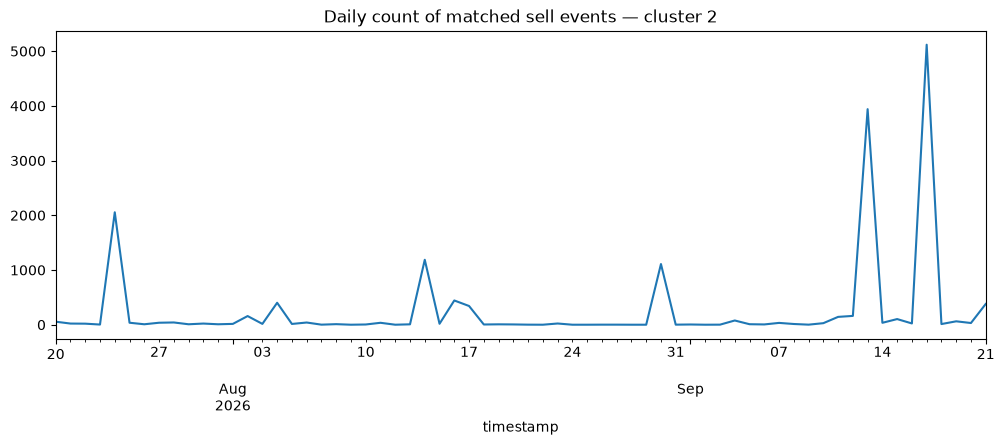

In [166]:
# is it recurring throughout, or clustered into a few distinct bursts within the 2 months?
cluster2_edges_matched.set_index("timestamp")["time_diff"].resample("D").count().plot(figsize=(12,4))
plt.title("Daily count of matched sell events — cluster 2")
plt.show()

In [167]:
cluster2_edges_matched["timestamp"].value_counts().head(10)

timestamp
2026-09-13 14:56:30+00:00    3143
2026-09-17 15:07:49+00:00    3028
2026-08-30 10:45:19+00:00     838
2026-08-14 17:46:36+00:00     610
2026-09-17 15:08:16+00:00     471
2026-08-04 09:07:11+00:00     372
2026-09-17 15:08:00+00:00     279
2026-09-21 14:47:14+00:00     228
2026-09-13 15:01:25+00:00     222
2026-09-17 15:08:04+00:00     185
Name: count, dtype: int64

In [168]:
print(cluster2_edges_matched["size_ratio"].describe())

count    16329.000000
mean         0.283992
std          0.329286
min          0.000001
25%          0.030522
50%          0.125574
75%          0.452465
max          1.000000
Name: size_ratio, dtype: float64


In [169]:
wallet_1440_partners = pd.concat([
    cluster2_edges_matched.loc[cluster2_edges_matched["source_id"] == 1440, "target_id"],
    cluster2_edges_matched.loc[cluster2_edges_matched["target_id"] == 1440, "source_id"]
])
print("Distinct counterparties for wallet 1440:", wallet_1440_partners.nunique())
print(wallet_1440_partners.value_counts().head(10))

Distinct counterparties for wallet 1440: 0
Series([], Name: count, dtype: int64)
